In [5]:
!pip install hdbscan scikit-learn pandas numpy matplotlib seaborn

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import hdbscan

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [7]:
# Memuat dataset Iris
iris = load_iris()

# Mengambil fitur dataset
X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Mengambil label asli
y = iris.target

# Menampilkan 5 data pertama
print("Lima Data Pertama:")
print(X.head())

print("\nJumlah Data:", X.shape[0])
print("Jumlah Fitur:", X.shape[1])

print("\nLabel Asli:")
print(iris.target_names)

Lima Data Pertama:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Jumlah Data: 150
Jumlah Fitur: 4

Label Asli:
['setosa' 'versicolor' 'virginica']


In [8]:
# Standardisasi data
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("\nStandardisasi berhasil!")
print("Ukuran data:", X_scaled.shape)


Standardisasi berhasil!
Ukuran data: (150, 4)


In [9]:
# Membuat model HDBSCAN
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=3,
    metric='euclidean',
    cluster_selection_method='eom'
)

# Melakukan clustering
cluster_labels = clusterer.fit_predict(X_scaled)

# Menambahkan hasil clustering
X['Cluster'] = cluster_labels
X['Original_Label'] = y

print("\nHasil Clustering:")
print(X.head(10))


Hasil Clustering:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

   Cluster  Original_Label  
0        1               0  
1        1               0  
2        1              

In [10]:
# Menghitung jumlah cluster
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)

# Menghitung jumlah noise
n_noise = np.sum(cluster_labels == -1)

print("\n===== HASIL HDBSCAN =====")
print("Jumlah Cluster:", n_clusters)
print("Jumlah Noise:", n_noise)
print("Jumlah Data:", len(cluster_labels))


===== HASIL HDBSCAN =====
Jumlah Cluster: 2
Jumlah Noise: 2
Jumlah Data: 150


In [11]:
# Membuat model PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Membuat DataFrame hasil PCA
pca_df = pd.DataFrame(
    X_pca,
    columns=['PCA 1', 'PCA 2']
)

pca_df['Cluster'] = cluster_labels
pca_df['Original_Label'] = y

print("\nHasil PCA:")
print(pca_df.head())

print("\nTotal Variance Explained:")
print(pca.explained_variance_ratio_.sum())


Hasil PCA:
      PCA 1     PCA 2  Cluster  Original_Label
0 -2.264703  0.480027        1               0
1 -2.080961 -0.674134        1               0
2 -2.364229 -0.341908        1               0
3 -2.299384 -0.597395        1               0
4 -2.389842  0.646835        1               0

Total Variance Explained:
0.9581320720000162


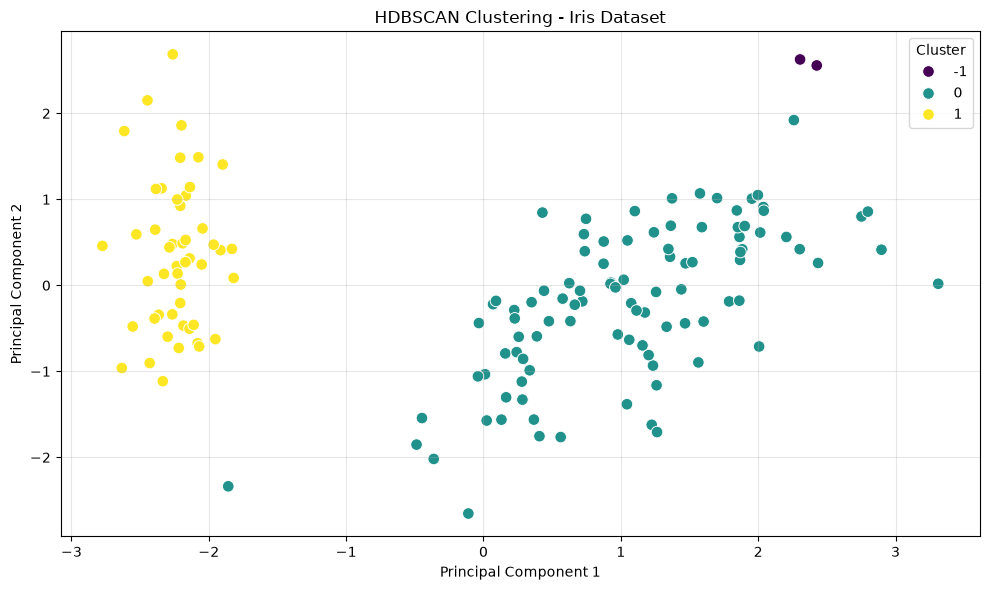

In [12]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PCA 1',
    y='PCA 2',
    hue='Cluster',
    palette='viridis',
    s=70
)

plt.title('HDBSCAN Clustering - Iris Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

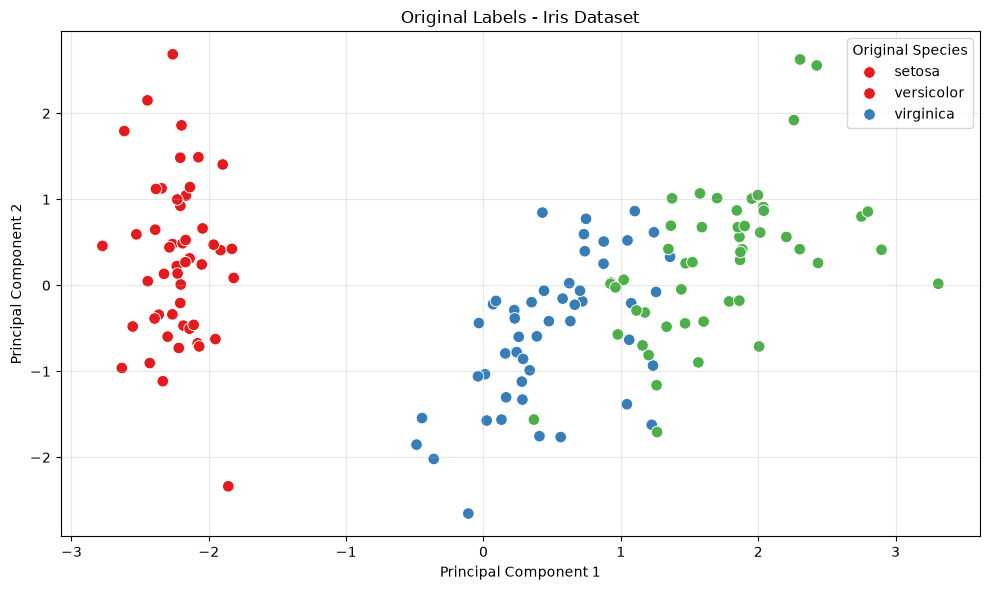

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PCA 1',
    y='PCA 2',
    hue='Original_Label',
    palette='Set1',
    s=70
)

plt.title('Original Labels - Iris Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend(
    title='Original Species',
    labels=iris.target_names
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# Membandingkan hasil clustering dengan label asli
ari_score = adjusted_rand_score(y, cluster_labels)

print("\n===== PERBANDINGAN LABEL =====")
print("Adjusted Rand Index:", round(ari_score, 4))

# Membuat tabel perbandingan
comparison = pd.crosstab(
    pd.Series(y, name='Original Label'),
    pd.Series(cluster_labels, name='HDBSCAN Cluster')
)

print("\nTabel Perbandingan:")
print(comparison)


===== PERBANDINGAN LABEL =====
Adjusted Rand Index: 0.5394

Tabel Perbandingan:
HDBSCAN Cluster  -1   0   1
Original Label             
0                 0   1  49
1                 0  50   0
2                 2  48   0


## Do the HDBSCAN clustering results correspond to the dataset's original labels?

HDBSCAN was applied to the Iris dataset using four numerical features. The clustering results produced 2 clusters and 2 noise points.

The comparison with the original labels shows that most Setosa samples were assigned to Cluster 1, while all Versicolor samples were assigned to Cluster 0. Most Virginica samples were also assigned to Cluster 0, with 2 samples classified as noise.

The Adjusted Rand Index (ARI) obtained was 0.5394, indicating a moderate agreement between the clustering results and the original labels.

Therefore, the HDBSCAN clustering results partially correspond to the original Iris labels, but they do not completely separate all three flower species. This happens because HDBSCAN groups data based on density rather than using the original class labels.